# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# cargar archivos

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage =pd.read_csv('/datasets/usage.csv')


In [5]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [6]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [7]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [8]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [9]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [10]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [11]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [12]:

# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [13]:
print(usage.isna().sum())
print (usage.isna().mean)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
<bound method NDFrame._add_numeric_operations.<locals>.mean of           id  user_id   type   date  duration  length
0      False    False  False  False     False    True
1      False    False  False  False      True   False
2      False    False  False  False      True   False
3      False    False  False  False     False    True
4      False    False  False  False     False    True
...      ...      ...    ...    ...       ...     ...
39995  False    False  False  False     False    True
39996  False    False  False  False     False    True
39997  False    False  False  False     False    True
39998  False    False  False  False      True   False
39999  False    False  False  False     False    True

[40000 rows x 6 columns]>


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [14]:
users["age"].describe()

count    4000.000000
mean       33.739750
std       123.232257
min      -999.000000
25%        32.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

- La columna `user_id` no tiene sentido explorarla, ya que es un identificador, no una medida
- La columna `age` presenta valores erroneos que distorsionan media, mediana, etc.

In [15]:
usage[["duration", "length"]].describe()

,duration,length
count,17924.000000,22104.000000
mean,5.202237,52.127398
std,6.842701,56.611183
min,0.000000,0.000000
25%,1.437500,37.000000
50%,3.500000,50.000000
75%,6.990000,64.000000
max,120.000000,1490.000000


In [16]:
usage['type'].unique()


array(['call', 'text'], dtype=object)

- Las columnas `id` y `user_id`no se exploraron porque son identificadores
- Las columnas `duration` y `length`corresponden a llamada y mensaje de texto,y son casi mutuamente excluyentes según el valor de type,lo cual explica la diferencia en sus conteos de valores no nulos frente al total de filas.

In [17]:
usage['duration'].notnull().sum() + usage['length'].notnull().sum()

40028

In [18]:
len(usage)

40000

In [19]:
# explorar columnas categóricas de users
print(users['city'].value_counts())
print(users['plan'].value_counts())

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` tiene un valor ? que representa datos faltantes o no capturados, afectando a 96 usuarios
- La columna `plan` se aprecia limpia, con 2 categorías definidas.

In [20]:
# explorar columna categórica de usage
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` tiene dos categorías sin valores vacíos


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
En el dataset users, la columna `age` presenta valores erroneos que distorsionan las estadísticas descriptivas.La columna city tiene un valor ? que representa datos faltantes o no capturados, afectando a 96 usuarios. En ambos casos tomaría la acción de imputar los datos faltantes.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [21]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])

In [22]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])


In [23]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()


array([2022, 2026, 2023, 2024])

En `reg_date`, se encuentra una fecha futura:2026.

In [24]:
usage['date'].dt.year.unique()


array([2024.,   nan])

En `date`, se encuentran usuarios sin fecha de baja, lo cual indica que continuan activos. 


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
Aparecen años sin transcurrir y deben convertirse a NaN antes del análisis. El objetivo es estandarizar antes del análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [25]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age']!=-999,'age'].median()
users.loc[users['age'] == -999, 'age']= age_mediana

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [26]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', np.nan)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [27]:
fecha_limite = pd.Timestamp('2024-12-31')
users.loc[users['reg_date'] > fecha_limite, 'reg_date'] = np.nan


# Verificar cambios
users['reg_date'].describe()

count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

In [28]:

users['reg_date'] = pd.to_datetime(users['reg_date'])
users['reg_date'].describe()


count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

In [29]:
print(users['reg_date'].dtype)


datetime64[ns]


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [30]:
usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending=False)


type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [31]:
usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending=False)


type
call    0.99933
text    0.00000
Name: length, dtype: float64

 En el caso de`duration`probablemente mide la duración de una llamada, así que para un mensaje de texto no aplica tener duración,por lo tanto los nulos en `duration` son MAR: dependen directamente de la columna type, no son aleatorios.  por eso casi todos son nulos. En el caso de`length`, que probablemente mide la longitud de un mensaje de texto, esto también es un caso de MAR: los nulos dependen de type, y representan una ausencia lógica de información, no un error de datos, por esto, se dejan como están.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [32]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg =usage.groupby('user_id').agg({'is_text': 'sum', 'is_call': 'sum', 'duration': 'sum'}).reset_index()
 

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [33]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text':'cant_mensajes', 'is_call':'cant_llamadas', 'duration': 'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [34]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = usage_agg.merge(users, on= "user_id",how="inner")
user_profile.head(5)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,5,10,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [35]:
user_profile.describe()


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,age
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.729432,5.524381,4.478120,23.317054,48.138285
std,1154.898108,2.358416,2.144238,18.168095,17.691541
min,10000.000000,0.000000,0.000000,0.000000,18.000000
25%,10999.500000,4.000000,3.000000,11.120000,33.000000
50%,12000.000000,5.000000,4.000000,19.780000,48.000000
75%,12999.500000,7.000000,6.000000,31.415000,63.000000
max,13999.000000,17.000000,15.000000,155.690000,79.000000


In [36]:

user_profile['plan'].value_counts(normalize=True)*100



Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

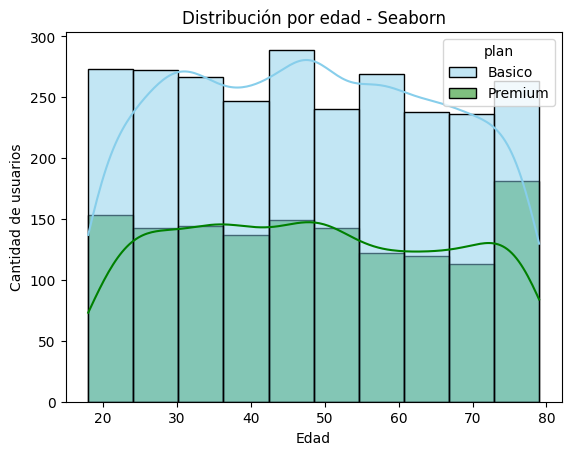

In [37]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], bins=10, kde=True)
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución por edad - Seaborn')
plt.show()

💡Insights: 
Distribución uniforme.La cantidad de usuarios no está concentrada en una sola etapa de la vida; se mantiene bastante estable y homogénea desde los 20 hasta los 80 años, con un promedio general que oscila entre los 200 y 280 usuarios por intervalo.
El plan Básico concentra la mayor proporción de usuarios en casi todos los grupos de edad en comparación con el plan Premium. El plan Premium mantiene una base constante de usuarios  en la mayoría de las edades, y destaca un ligero repunte o mayor proporción relativa en el segmento de adultos mayores cerca de los 80 años.

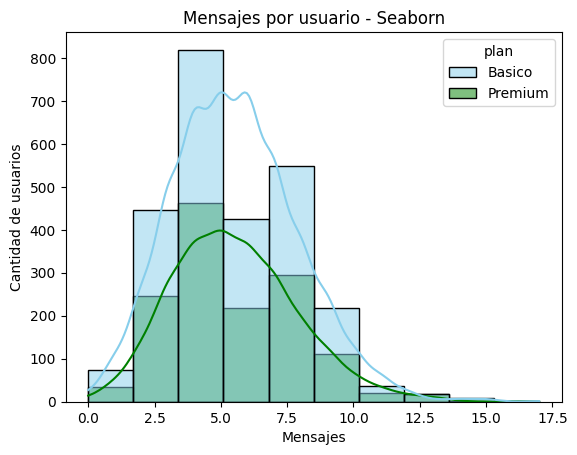

In [38]:
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], bins=10, kde=True)
plt.xlabel('Mensajes')
plt.ylabel('Cantidad de usuarios')
plt.title('Mensajes por usuario - Seaborn')
plt.show()


💡Insights: 
- Distribución sesgada a la derecha con un pico claro alrededor de los 5 mensajes y una cola que se extiende hacia los valores más altos.
 La gran mayoría de los usuarios (en ambos planes) concentran su actividad entre los 2.5 y 7.5 mensajes. La cola hacia la derecha indica que solo una minoría de usuarios envía una cantidad elevada de mensajes (superando los 12-15).

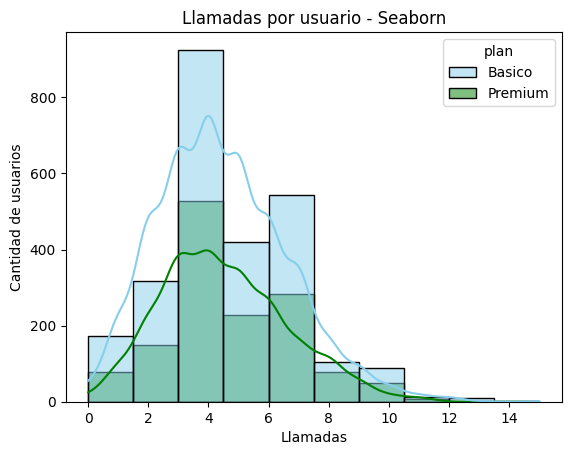

In [39]:
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], bins=10, kde=True)
plt.xlabel('Llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Llamadas por usuario - Seaborn')
plt.show()


💡Insights: 
- Distribución sesgada a la derecha, con un pico centrado alrededor de las 4 llamadas y una cola que disminuye gradualmente hacia los valores más altos.
 El plan Básico concentra una mayor cantidad de usuarios en casi todos los intervalos de llamadas en comparación con el plan Premium , manteniendo una proporción similar en la forma de la distribución pero con una escala superior de usuarios activos.

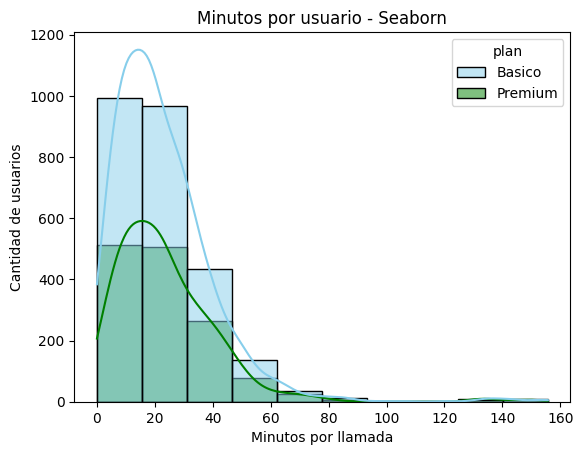

In [40]:
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], bins=10, kde=True)
plt.xlabel('Minutos por llamada')
plt.ylabel('Cantidad de usuarios')
plt.title('Minutos por usuario - Seaborn')
plt.show()


💡Insights: 
- Distribución sesgada a la derecha, con un pico muy pronunciado en el intervalo inicial (alrededor de los 15-20 minutos) y unacola larga que se extiende hacia la derecha con valores más altos alcanzando más de 140 minutos.
El plan Básico concentra una cantidad de usuarios notablemente mayor que el plan Premium en los rangos de menor duración (hasta los 40 minutos), manteniendo ambos planes un comportamiento decreciente similar a medida que aumentan los minutos por llamada.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

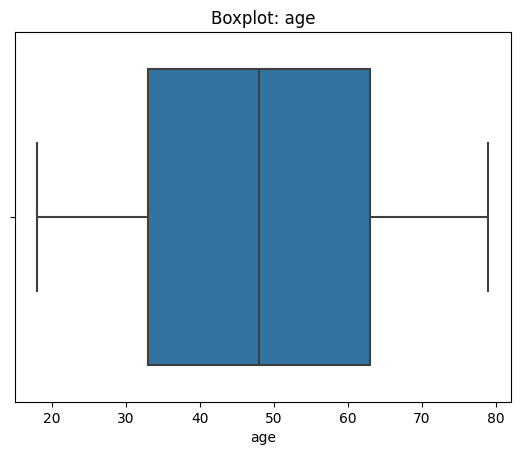

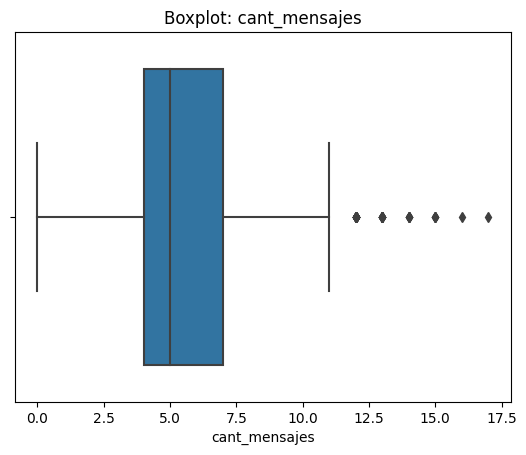

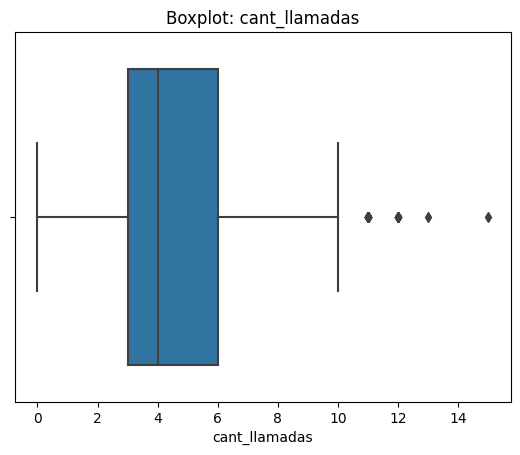

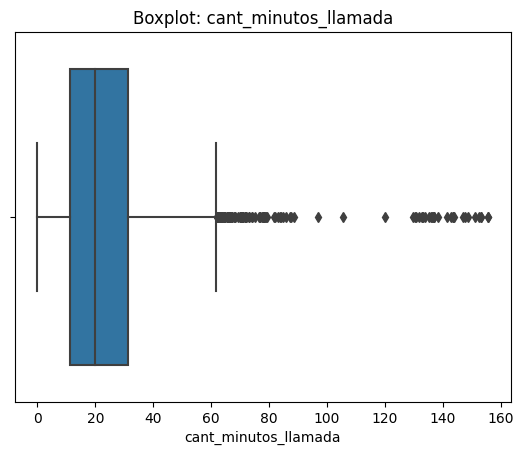

In [41]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- age:No presenta outliers. Los datos de la edad se encuentran simétricamente distribuidos en torno a la mediana (cerca de los 48-50 años), abarcando desde aproximadamente los 18 hasta los 80 años.   
- cant_mensajes:  Sí presenta outliers. Se visualizan varios puntos individuales hacia la derecha.La mayoría de los usuarios concentran su cantidad de mensajes entre 4 y 7, con una mediana cercana a los 5.
- cant_llamadas: Sí presenta outliers. Hay valores atípicos representados como puntos aislados a la derecha del bigote superior.El comportamiento de las llamadas está concentrado entre las 3 y 6 llamadas por usuario.
- cant_minutos_llamada:Sí presenta outliers. Cuenta con una cantidad importante de valores atípicos extendidos fuertemente hacia la derecha. La gran mayoría de los usuarios acumulan una baja cantidad de minutos en llamadas (concentrados mayormente por debajo de los 35 minutos).

In [42]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr

    outliers = user_profile[user_profile[col] > limite_superior]
    print(f"columna: {col}")
    print(f"límite superior: {limite_superior}")
    print(f"cantidad de registros atípicos (outliers): {len(outliers)}\n")
    


columna: cant_mensajes
límite superior: 11.5
cantidad de registros atípicos (outliers): 46

columna: cant_llamadas
límite superior: 10.5
cantidad de registros atípicos (outliers): 30

columna: cant_minutos_llamada
límite superior: 61.8575
cantidad de registros atípicos (outliers): 109



In [43]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?
- La respuesta en los tres casos es mantener los outliers, debido a que estos outliers representan usuarios reales con consumo alto ("heavy users"), no errores de datos, por lo que tiene sentido mantenerlos en el análisis en vez de eliminarlos, ya que son parte legítima del comportamiento de los clientes y pueden ser valiosos para el negocio (por ejemplo, para identificar usuarios que podrían necesitar un plan superior).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [44]:
def grupo_uso(row):

    if row['cant_llamadas']< 5 and row['cant_mensajes']< 5:
        return 'Bajo uso'
    elif row ['cant_llamadas'] < 10 and row ['cant_mensajes']< 10:
        return 'Uso medio'
    else:
        return 'Alto uso'
        
user_profile['grupo_uso']=user_profile.apply(grupo_uso, axis=1)

In [45]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [46]:
def grupo_edad(row):
    if row ['age'] < 30:
        return 'Joven'
    elif row ['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'
user_profile['grupo_edad']=user_profile.apply(grupo_edad, axis=1)

In [47]:
user_profile['grupo_edad'].value_counts()

Adulto          2017
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

In [48]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso,grupo_edad
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio,Adulto
1,10001,5,10,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso,Adulto
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio,Adulto
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso,Adulto Mayor
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

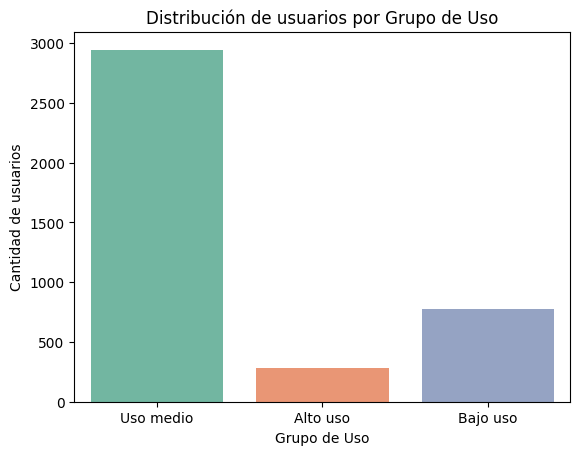

In [49]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', palette='Set2')
plt.title('Distribución de usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

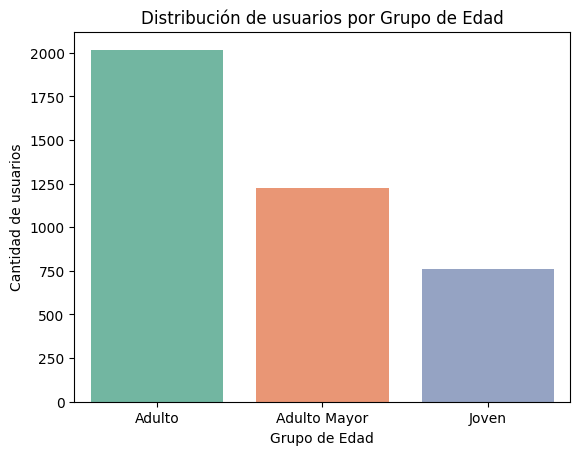

In [50]:
sns.countplot(data=user_profile, x='grupo_edad', palette='Set2')
plt.title('Distribución de usuarios por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()




In [53]:
pd.crosstab(user_profile['grupo_edad'],user_profile['grupo_uso'])

grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,153,364,1500
Adulto Mayor,74,257,891
Joven,51,157,552



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Problemas detectados en los datos 
Durante la exploración y limpieza inicial, se detectaron problemas de calidad de datos en una pequeña, pero importante, proporción de los registros (sobre un total de 4.000 clientes):

Edades inválidas: Se encontraron 55 registros con la edad ingresada como -999. Fueron corregidos imputando la mediana de edad del resto de la base.

Ciudades no capturadas: 96 registros contenían el valor  "?" en la columna ciudad. Estos fueron transformados a valores nulos (NaN) para evitar distorsiones en agrupaciones geográficas.

Fechas de registro futuras: Se detectaron 40 usuarios con fechas de registro en el año 2026, algo imposible ya que el análisis contempla datos hasta 2024. Fueron reemplazados por valores nulos para estandarizar el periodo de análisis.

Duración y longitud de uso (MAR): Se confirmó la presencia de una alta tasa de valores nulos lógicos (Missing At Random) en el archivo de uso. Las llamadas no tienen longitud de caracteres y los mensajes de texto no tienen duración en minutos, lo cual es el comportamiento correcto de los sistemas de captura.


🔍 **Segmentos por Edad**
-
Los clientes fueron divididos en tres segmentos demográficos:
Adulto (30 a 59 años): Representa el 50.4% de la base total con 2,017 usuarios (153 en Alto uso, 364 en Bajo uso y 1,500 en Uso medio).   Presenta un comportamiento masivo predominantemente centrado en el Uso medio(74.4% de su segmento) y aporta la mayor cantidad  de usuarios de Alto uso (153 usuarios). 

Adulto Mayor (60+ años): Representa un volumen significativo con 1.222 usuarios (30.6%).  (74 en Alto uso, 257 en Bajo uso y 891 en Uso medio).  Presenta una fuerte concentración en Uso medio (72.9%) y una proporción estable de consumo.

Joven (Menores de 30 años): Es el grupo más pequeño con 760 usuarios (19%), Constituye el 19.0% de la base con 760 usuarios (51 en Alto uso, 157 en Bajo uso y 552 en Uso medio). Muestra una distribución equivalente a los otros grupos (72.6% en Uso medio) ,  a pesar de ser la población más pequeña en la muestra.

💡 **Recomendaciones**
-El análisis estadístico reveló la presencia de outliers legítimos en las tres métricas de consumo:
Mensajes: Clientes enviando más de 11.5 mensajes (hasta 17).
Llamadas: Clientes con más de 10.5 llamadas (hasta 15).
Minutos de llamada: Clientes superando los 61.8 minutos, con extremos que llegan hasta más de 155 minutos al mes.

-Estos registros no son errores de sistema, sino clientes altamente rentables o con potencial de upselling. Si estos outliers tienen el plan Básico, están generando ingresos adicionales altos por consumo extra, pero también son altamente vulnerables a ofertas de la competencia con planes ilimitados.

Recomendaciones comerciales y de producto

Campaña enfocada a usuarios en el segmento de "Alto Uso" (y específicamente los outliers) que actualmente tienen el plan Básico que consiste en ofrecerles una migrar al plan Premium demostrándoles qué ahorrarán dinero al evitar recargos por uso extra. 
Estrategias focalizadas por Edad: Dado que los Jóvenes son la base más pequeña, se recomienda una campaña de adquisición de clientes en redes sociales y canales digitales para atraer más público de este rango. En paralelo, para los "Adultos Mayores", se sugiere simplificar el soporte técnico ya que son el grupo más propenso a contratar planes Premium. 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`